# Forecast ensemble performance and initial shock

## Purpose

Two figures for the hindcasts, each in its own section:

- **Daily performance** (section 3, main manuscript figure): daily ensemble-mean RMSE and spread/error consistency of PSL, TREFHT, PRECT, and FLUT for every experiment, plus bias and fair CRPS; for the larger ensembles the RMSE panels also show 10-member subsets, so every experiment is compared at the same ensemble size.
- **Initial shock** (section 4, validation / supplement): the native 6-hourly adjustment right after initialization, mainly PSL and TREFHT (TS as a check): regional mean $|dX/dt|$ and $|dX/dt|$ normalized by its settled level, with the reference tendency.

The comparisons to keep in view are CTRL10 → CAPT10 → DART10 (initialization strategy at equal ensemble size) and DART10 → DART20 → DART40 (ensemble size; the subset test separates the effect of averaging more members).

## Inputs

6-hourly member output `ts/6hourly/<variable>.EN##.<year>.nc` of the hindcasts registered in `util/bias_metrics.py`, and references under `OBSERVATION_ROOT`: ERA5 6-hourly (PSL, TREFHT, TS), GPCP daily (PRECT; GPM IMERG and ERA5 are available as sensitivity choices), NOAA interpolated OLR daily (FLUT).

## Processing

**Daily performance: 6-hourly member fields → daily member fields → ensemble diagnostics.** Each member is first aggregated to 24-hour forecast-lead bins (day $k$ covers lead hours $(24(k-1), 24k]$; independent of the start hour): PSL, stored as instantaneous values, by a time-weighted (trapezoid) mean of the 0, 6, 12, 18, and 24 h states; TREFHT, PRECT (a rate, kept as mm day$^{-1}$), and FLUT, stored as 6-hour interval means, by the mean of the four intervals. Day 1 is the first complete 24-hour interval, and the lead-0 snapshot never enters an interval-mean variable. The stored temporal semantics are checked before processing. The references are averaged over the same bins. Ensemble mean, spread, bias, RMSE, and fair CRPS are then computed from the daily fields, on the same gridpoints and cos-latitude weights for every metric (the region intersected with the reference coverage).

**Initial shock:** native 6-hourly regional diagnostics (see Notes), with its own variables and windows.

## Outputs

Daily metrics caches (`daily_skill/`), shock caches, and summary CSVs under `DIAGNOSTIC_OUTPUT_ROOT/data/fcst_atm_ensemble_ts/`; figures under `DIAGNOSTIC_OUTPUT_ROOT/figure/fcst_atm_ensemble_ts/daily_performance/` and `.../shock/`. Review the user setup, then run the notebook from top to bottom; each section can also be rerun on its own after the shared setup.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## 2. User setup

Paths; the season, experiments, and regions (shared by both figures); then the settings of each figure; and run options. Edit this cell for normal changes.


In [2]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")  # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")  # land mask
WORKFLOW_NAME = "fcst_atm_ensemble_ts"

# What to compare
SEASON = "S0"  # "S0": Jan-Feb 2012 hindcasts; "S1": Jun-Jul 2012 hindcasts
# S0: CTRL10-S0, CAPT10-S0, DART10-S0, DART20-S0, DART40-S0
# S1: CTRL10-S1, CAPT10-S1, DART40-S1
EXPERIMENTS = ("CTRL10-S0", "CAPT10-S0", "DART10-S0", "DART20-S0", "DART40-S0")
# global, 60S-60N (common domain if PRECT uses GPM), land, ocean, Tropics,
# CONUS, NHMidLat, NINO3.4, MAR_CONT; one figure per region
REGIONS = ("global",)

# ---- Daily performance (section 3) ----
DAILY = dict(
    variables=("PSL", "TREFHT", "PRECT", "FLUT"),
    references={"PRECT": "GPCP"},  # PRECT sensitivity: "GPM" (60S-60N only), "ERA5"
    max_day=30,  # forecast days shown in the figure
    n_subsets=100,  # random subsets for ensembles larger than subset_size
    subset_size=10,
    seed=42,
    baselines=("CTRL10", "CAPT10"),  # % RMSE changes in the summary table
)

# ---- Initial shock (section 4; native 6-hourly output) ----
SHOCK = dict(
    frequency="6hourly",
    variables=("PSL", "TREFHT", "TS"),
    core=("CTRL10", "CAPT10", "DART10"),  # solid; other experiments dashed (sensitivity)
    zoom_days=10,  # lead days shown
    plots=("tendency",),  # add "timeseries" for member time series
)
SHOCK_DAYS = 2.0  # window treated as the initial shock (lead days)
SETTLED_DAYS = (10.0, 30.0)  # window taken as the adjusted state
TOLERANCE = 0.2  # adjustment lasts while the 1-day running |dX/dt| exceeds (1 + TOLERANCE) x settled

VALIDATE_SEMANTICS = True  # check stored time semantics and the daily aggregation once
MAX_MEMBERS = None  # e.g. 2 for a quick test (no subsets then); caches record the ensemble size
FORCE_COMPUTE = True
SHOW = True
FIGURE_DPI = 200

## 3. Shared setup

Paths, experiments, labels, and the figure setup (`FONTZ`) used by both figures.


In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.bias_metrics import experiment_registry
from util.forecast_ensemble_ts import validate_regions

validate_regions(REGIONS)
data_dir, figure_root = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)
cases = {SEASON: tuple(EXPERIMENTS)}
registry = experiment_registry(INPUT_DATA_ROOT, SEASON, "fc")
unknown = set(EXPERIMENTS) - set(registry)
if unknown:
    raise ValueError(f"{SEASON}: {sorted(unknown)} unavailable; choose from {list(registry)}")
labels = {name: registry[name]["label"] for name in EXPERIMENTS}
print(f"{SEASON} {list(EXPERIMENTS)} | regions {list(REGIONS)}")

# ---- Figure setup (both figures) ----
FONTZ = 16  # base font size; panel titles, axis labels, ticks, and legend scale from it
FIGURE_TITLE = True  # False: no title above the panels (details go in the caption)


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


S0 ['CTRL10-S0', 'CAPT10-S0', 'DART10-S0', 'DART20-S0', 'DART40-S0'] | regions ['global']


## 4. Daily performance

### Driver: validate, read, process, and save data

Check the stored time semantics, reuse valid caches or build missing ones, then compute and save the summary table.


In [4]:
from util.forecast_daily_skill import (
    check_temporal_semantics, daily_skill_summary, read_or_process_daily_skill,
    validate_daily_aggregation, validate_daily_mode,
)

daily = validate_daily_mode("daily_performance", {"daily_performance": DAILY})
print(f"daily performance: {daily}")
if VALIDATE_SEMANTICS:
    first = registry[EXPERIMENTS[0]]
    display(check_temporal_semantics(first, daily["variables"], first["period"]))
    display(pd.DataFrame([validate_daily_aggregation(first, v, first["period"]) for v in daily["variables"]]))

daily_results, registries, failures = read_or_process_daily_skill(
    cases, daily["variables"], data_root=INPUT_DATA_ROOT, reference_root=OBSERVATION_ROOT,
    cache_dir=data_dir, regions=REGIONS, landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc",
    references=daily["references"], max_members=MAX_MEMBERS, n_subsets=daily["n_subsets"],
    subset_size=daily["subset_size"], seed=daily["seed"], force_compute=FORCE_COMPUTE,
)
for season, variable, experiment, error in failures:
    print(f"[SKIPPED] {season} {variable} {experiment}: {error}")
daily_summary = daily_skill_summary(daily_results, baselines=daily["baselines"])
table_path = data_dir / f"summary_{SEASON}_fc_daily_performance.csv"
daily_summary.to_csv(table_path, index=False)
print(f"[TABLE] {table_path}")


daily performance: {'references': {'PRECT': 'GPCP'}, 'max_day': 30, 'n_subsets': 100, 'subset_size': 10, 'seed': 42, 'baselines': ('CTRL10', 'CAPT10'), 'variables': ('PSL', 'TREFHT', 'PRECT', 'FLUT')}


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,PRECT,time: mean,m/s,0.0,6.0,width-weighted mean of interval means,ok
3,FLUT,time: mean,W/m2,0.0,6.0,width-weighted mean of interval means,ok


,variable,stored_daily_file,daily_file_cell_methods,comparison,max_abs_difference,mean_abs_difference,mean_abs_value
0,PSL,ts/daily_mean,time: mean (00Z to 24Z of the day) (average of...,compared,6.068932,5.404141e-01,1008.316675
1,TREFHT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000031,8.921250e-06,278.162845
2,PRECT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000027,1.100693e-07,2.444765
3,FLUT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,5.052343,1.397050e-01,225.003118


[WRITE] CTRL10-S0_PSL_201201-201202_daily_skill.nc (forced)
[WRITE] CAPT10-S0_PSL_201201-201202_daily_skill.nc (forced)
[WRITE] DART10-S0_PSL_201201-201202_daily_skill.nc (forced)
[WRITE] DART20-S0_PSL_201201-201202_daily_skill.nc (forced)
[WRITE] DART40-S0_PSL_201201-201202_daily_skill.nc (forced)
[WRITE] CTRL10-S0_TREFHT_201201-201202_daily_skill.nc (forced)
[WRITE] CAPT10-S0_TREFHT_201201-201202_daily_skill.nc (forced)
[WRITE] DART10-S0_TREFHT_201201-201202_daily_skill.nc (forced)
[WRITE] DART20-S0_TREFHT_201201-201202_daily_skill.nc (forced)
[WRITE] DART40-S0_TREFHT_201201-201202_daily_skill.nc (forced)
[WRITE] CTRL10-S0_PRECT_201201-201202_daily_skill.nc (forced)
[WRITE] CAPT10-S0_PRECT_201201-201202_daily_skill.nc (forced)
[WRITE] DART10-S0_PRECT_201201-201202_daily_skill.nc (forced)
[WRITE] DART20-S0_PRECT_201201-201202_daily_skill.nc (forced)
[WRITE] DART40-S0_PRECT_201201-201202_daily_skill.nc (forced)
[WRITE] CTRL10-S0_FLUT_201201-201202_daily_skill.nc (forced)
[WRITE] CAPT10

### Figure

The 4 x 2 performance figure, with the 10-member subsets on the RMSE panels; panel labels are short ((a) Ensemble-Mean RMSE (PSL), (b) Spread/RMSE (PSL), ...) and the details are printed and saved as the figure caption (`<figure>.caption.txt`).


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/daily_performance/daily_performance_global_S0_fc.png
[CAPTION] Daily ensemble performance of the S0 hindcasts over global for forecast days 1-30. Left column: RMSE of the daily ensemble mean; right column: ensemble spread over RMSE, with the spread corrected for ensemble size, S*sqrt((N+1)/N), so that 1 (dashed line) marks a statistically consistent ensemble. Daily values are 24-h forecast-lead means built from the 6-hourly output. References: PSL ERA5; TREFHT ERA5; PRECT GPCP; FLUT NOAA OLR. For ensembles larger than 10 members, dashed lines and shading show the mean and 5-95% range of the RMSE of 100 random 10-member subsets.


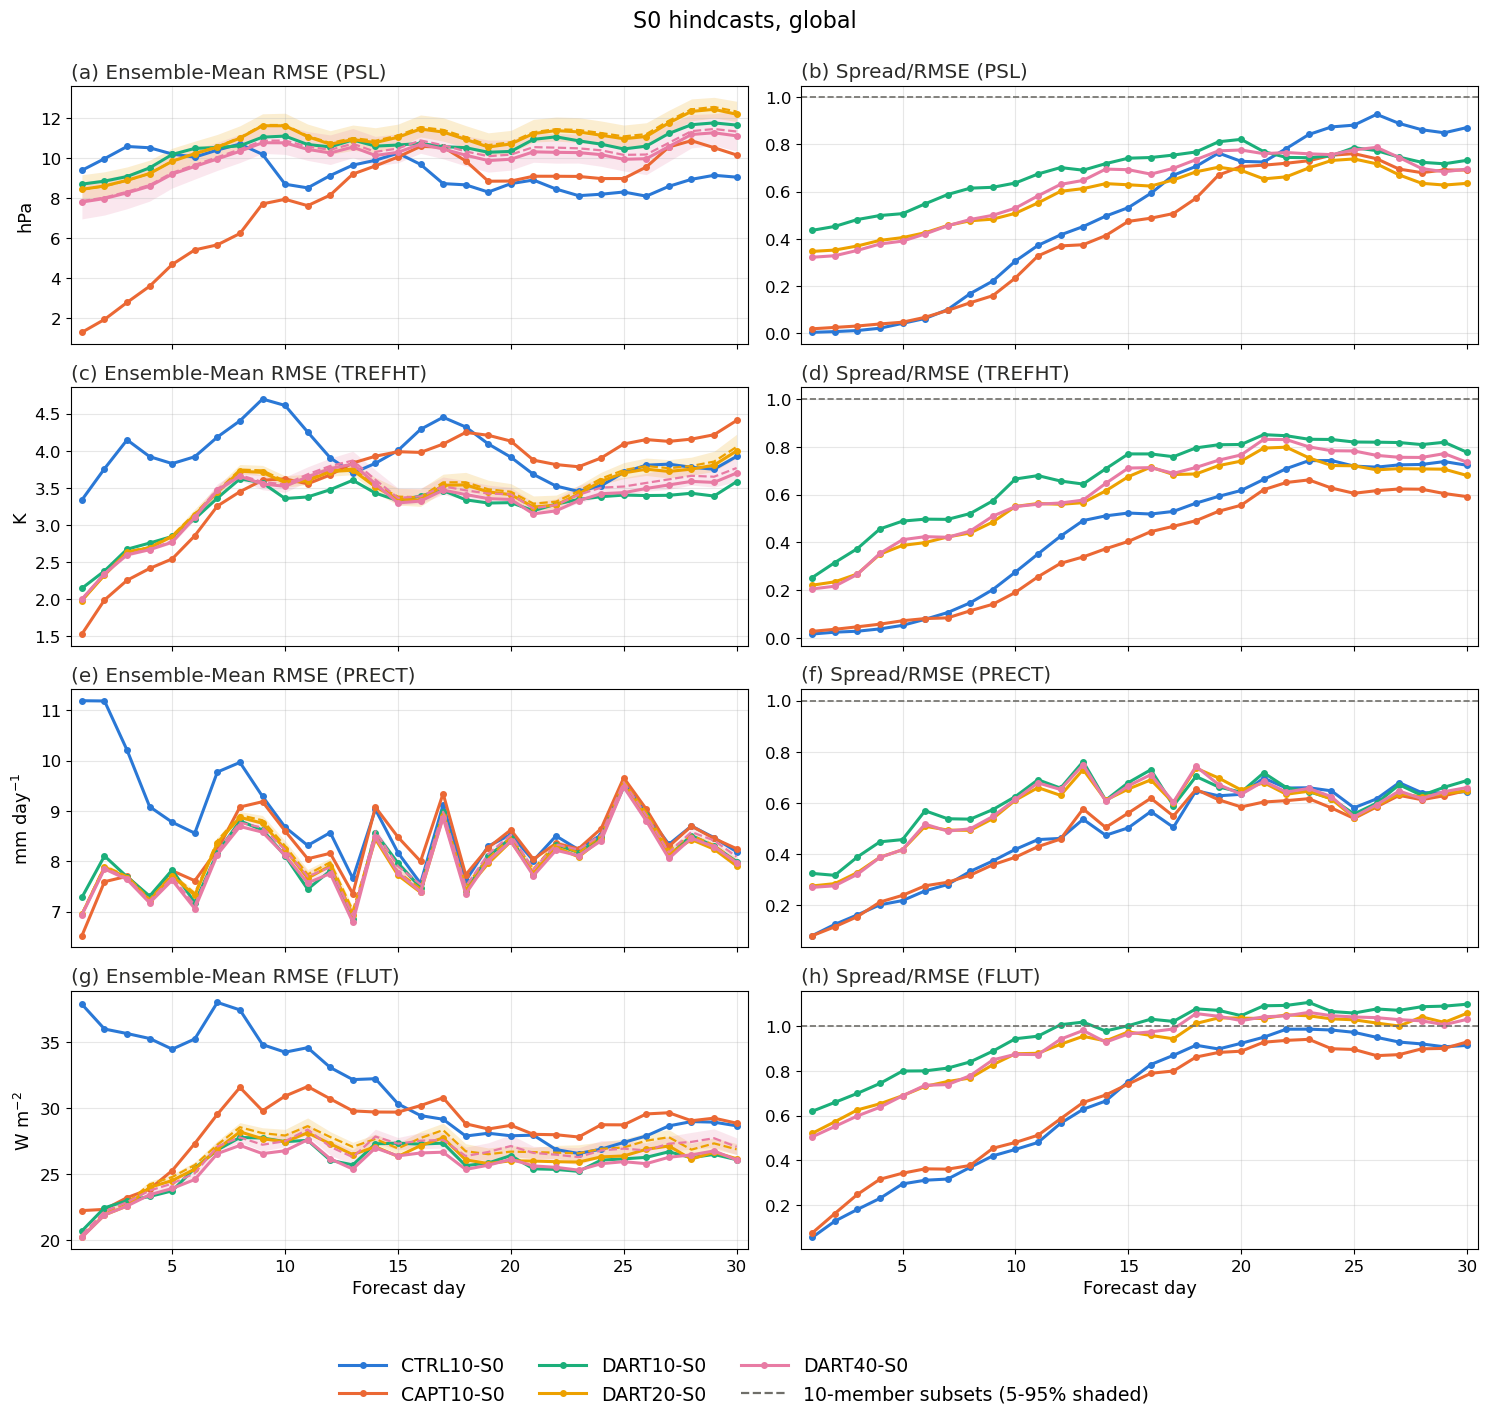

In [5]:
figure_dir = figure_root / "daily_performance"
figure_dir.mkdir(parents=True, exist_ok=True)

from util.forecast_daily_skill import plot_daily_performance, results_colors
colors = results_colors(daily_results)
for region in REGIONS:
    fig = plot_daily_performance(daily_results[SEASON], region, labels=labels, colors=colors,
                                 max_day=daily["max_day"], fontz=FONTZ,
                                 title=f"{SEASON} hindcasts, {region}" if FIGURE_TITLE else "")
    output = figure_dir / f"daily_performance_{region}_{SEASON}_fc.png"
    fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {output}")
    # Caption with the details left out of the panel labels; saved next to the figure.
    any_ds = next(iter(next(iter(daily_results[SEASON].values())).values()))
    refs = {v: next(iter(daily_results[SEASON][v].values())).attrs.get("reference", "") for v in daily_results[SEASON]}
    caption = (
        f"Daily ensemble performance of the {SEASON} hindcasts over {region} for forecast days 1-{daily['max_day']}. "
        "Left column: RMSE of the daily ensemble mean; right column: ensemble spread over RMSE, with the spread "
        "corrected for ensemble size, S*sqrt((N+1)/N), so that 1 (dashed line) marks a statistically consistent ensemble. "
        "Daily values are 24-h forecast-lead means built from the 6-hourly output. References: "
        + "; ".join(f"{v} {refs[v]}" for v in refs) + ". "
        f"For ensembles larger than {any_ds.attrs.get('subset_size')} members, dashed lines and shading show the mean and "
        f"5-95% range of the RMSE of {any_ds.attrs.get('n_subsets')} random {any_ds.attrs.get('subset_size')}-member subsets."
    )
    output.with_suffix(".caption.txt").write_text(caption + "\n")
    print("[CAPTION]", caption)
    if not SHOW:
        plt.close(fig)


### Summary table


In [6]:
display(daily_summary.round(3))


,season,variable,units,experiment,members,region,reference,rmse_days1-3,bias_days1-3,crps_fair_days1-3,...,rmse_days4-10_subset_p05,rmse_days4-10_subset_p95,rmse_days1-3_vs_CTRL10_pct,rmse_days1-3_subset_vs_CTRL10_pct,rmse_days4-10_vs_CTRL10_pct,rmse_days4-10_subset_vs_CTRL10_pct,rmse_days1-3_vs_CAPT10_pct,rmse_days1-3_subset_vs_CAPT10_pct,rmse_days4-10_vs_CAPT10_pct,rmse_days4-10_subset_vs_CAPT10_pct
0,S0,PSL,hPa,CTRL10-S0,10,global,ERA5,9.983,-0.043,6.206,...,NaN,NaN,0.000,NaN,0.000,NaN,398.331,NaN,71.593,NaN
1,S0,PSL,hPa,CAPT10-S0,10,global,ERA5,2.003,0.064,1.131,...,NaN,NaN,-79.933,NaN,-41.723,NaN,0.000,NaN,0.000,NaN
2,S0,PSL,hPa,DART10-S0,10,global,ERA5,8.877,-8.343,6.417,...,NaN,NaN,-11.076,NaN,3.841,NaN,343.133,NaN,78.184,NaN
3,S0,PSL,hPa,DART20-S0,20,global,ERA5,8.647,-8.150,6.560,...,10.090,11.227,-13.379,-13.495,4.684,4.914,331.659,331.079,79.631,80.026
4,S0,PSL,hPa,DART40-S0,40,global,ERA5,8.017,-7.503,6.238,...,9.256,10.783,-19.689,-19.201,-2.186,-1.340,300.214,302.646,67.843,69.293
5,S0,TREFHT,K,CTRL10-S0,10,global,ERA5,3.748,0.122,2.097,...,NaN,NaN,0.000,NaN,0.000,NaN,94.855,NaN,36.022,NaN
6,S0,TREFHT,K,CAPT10-S0,10,global,ERA5,1.923,0.074,0.936,...,NaN,NaN,-48.680,NaN,-26.482,NaN,0.000,NaN,0.000,NaN
7,S0,TREFHT,K,DART10-S0,10,global,ERA5,2.399,0.086,1.019,...,NaN,NaN,-35.984,NaN,-23.596,NaN,24.738,NaN,3.926,NaN
8,S0,TREFHT,K,DART20-S0,20,global,ERA5,2.313,0.083,1.006,...,3.275,3.372,-38.293,-38.213,-21.827,-21.395,20.239,20.394,6.332,6.919
9,S0,TREFHT,K,DART40-S0,40,global,ERA5,2.313,0.097,1.005,...,3.218,3.323,-38.294,-38.212,-23.122,-22.708,20.237,20.397,4.571,5.134


## 5. Initial shock (6-hourly)

### Driver: read, process, and save data

The native 6-hourly output after initialization (`SHOCK` settings, `SHOCK_DAYS`, `SETTLED_DAYS`); reuse valid caches or build missing ones, then compute and save the shock summary.


In [7]:
from util.forecast_ensemble_ts import read_or_process_ensemble_ts, shock_summary_table, validate_mode

shock = validate_mode("shock", {"shock": SHOCK})
print(f"initial shock: {shock}")
if VALIDATE_SEMANTICS:
    first = registry[EXPERIMENTS[0]]
    display(check_temporal_semantics(first, shock["variables"], first["period"], frequency=shock["frequency"]))

shock_results, shock_registries, failures = read_or_process_ensemble_ts(
    cases, shock["variables"], data_root=INPUT_DATA_ROOT, cache_dir=data_dir,
    frequency=shock["frequency"], regions=REGIONS, landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc",
    reference_root=OBSERVATION_ROOT, references=shock["references"],
    max_members=MAX_MEMBERS, force_compute=FORCE_COMPUTE,
)
for season, variable, experiment, error in failures:
    print(f"[SKIPPED] {season} {variable} {experiment}: {error}")
shock_summary = shock_summary_table(shock_results, shock_days=SHOCK_DAYS, settled_days=SETTLED_DAYS,
                                    tolerance=TOLERANCE)
table_path = data_dir / f"summary_{SEASON}_fc_shock.csv"
shock_summary.to_csv(table_path, index=False)
print(f"[TABLE] {table_path}")


initial shock: {'references': {}, 'member_display': 'members', 'zoom_days': 10, 'plots': ('tendency',), 'core': ('CTRL10', 'CAPT10', 'DART10'), 'kind': 'shock', 'frequency': '6hourly', 'variables': ('PSL', 'TREFHT', 'TS')}


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,TS,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/dask/array/core.py:5097: PerformanceWarning: Increasing number of chunks by factor of 10
  result = blockwise(


[WRITE] CTRL10-S0_PSL_6hourly_201201-201202_ensemble_ts.nc (forced)


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/dask/array/core.py:5097: PerformanceWarning: Increasing number of chunks by factor of 10
  result = blockwise(


...

[WRITE] DART10-S0_TS_6hourly_201201-201202_ensemble_ts.nc (forced)


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/dask/array/core.py:5097: PerformanceWarning: Increasing number of chunks by factor of 20
  result = blockwise(


[WRITE] DART20-S0_TS_6hourly_201201-201202_ensemble_ts.nc (forced)


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/dask/array/core.py:5097: PerformanceWarning: Increasing number of chunks by factor of 35
  result = blockwise(


[WRITE] DART40-S0_TS_6hourly_201201-201202_ensemble_ts.nc (forced)
[TABLE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_atm_ensemble_ts/summary_S0_fc_shock.csv


### Figures

The tendency figure (`(a) |dX/dt| (PSL)`, `(b) Normalized |dX/dt| (PSL)`, ...; core experiments solid, others dashed, the reference dotted) and the shock-summary bars, with the same `FONTZ` as above.


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/shock_tendency_global_S0_fc_shock.png
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/shock_summary_global_S0_fc_shock.png


[PosixPath('/compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/shock_summary_global_S0_fc_shock.png')]

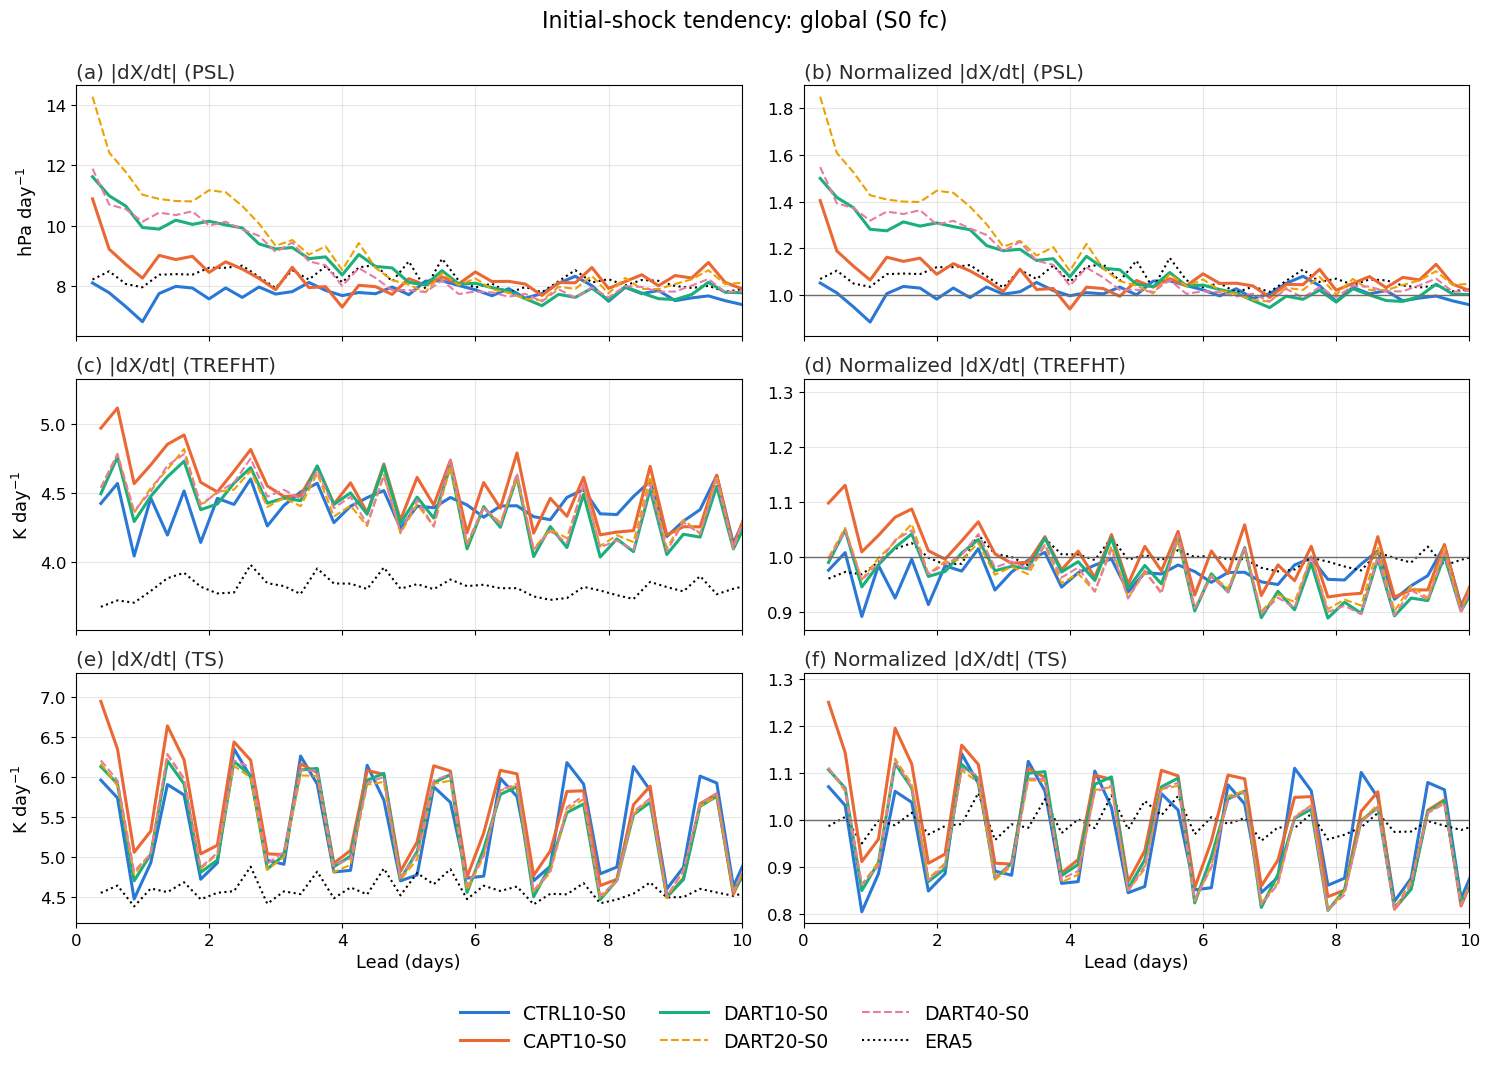

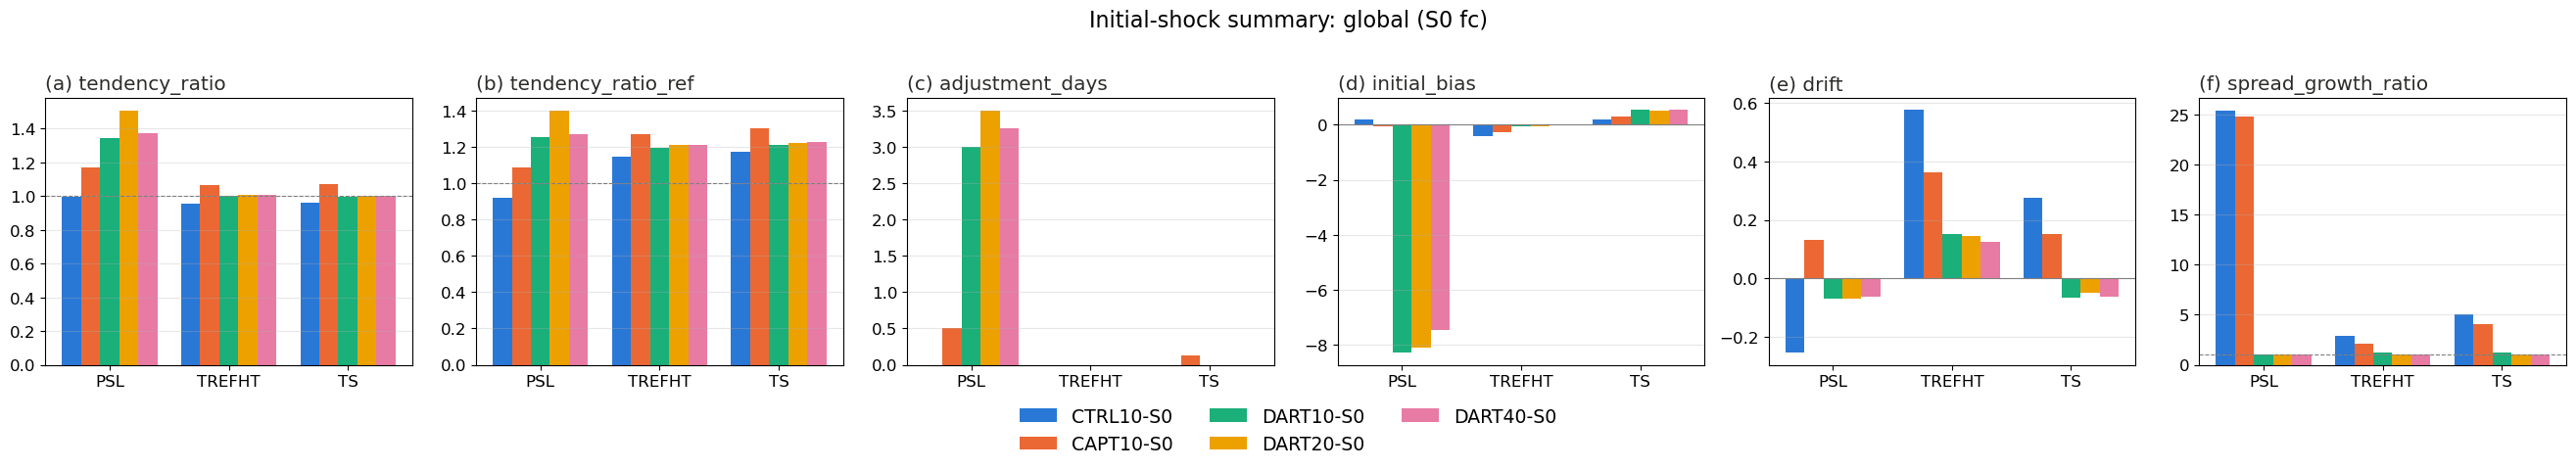

In [8]:
from util.forecast_ensemble_ts import plot_ensemble_ts_figures, plot_shock_summary_figures, results_colors

figure_dir = figure_root / "shock"
colors = results_colors(shock_results)
plot_ensemble_ts_figures(
    shock_results, shock_registries, regions=REGIONS, figure_dir=figure_dir, tag="shock", plots=shock["plots"],
    colors=colors, core=shock["core"], settled_days=SETTLED_DAYS, zoom_days=shock["zoom_days"],
    member_display=shock["member_display"], dpi=FIGURE_DPI, show=SHOW, fontz=FONTZ, title=FIGURE_TITLE,
)
plot_shock_summary_figures(shock_summary, figure_dir=figure_dir, tag="shock", colors=colors,
                           dpi=FIGURE_DPI, show=SHOW, fontz=FONTZ, title=FIGURE_TITLE)


### Summary table


In [9]:
display(shock_summary.round(3))


,season,experiment,label,variable,region,units,tendency_ratio,tendency_ratio_ref,adjustment_days,initial_bias,drift,spread_growth_ratio
0,S0,CTRL10-S0,CTRL10-S0,PSL,global,hPa,0.995,0.921,0.000,0.175,-0.255,25.407
1,S0,CAPT10-S0,CAPT10-S0,PSL,global,hPa,1.167,1.089,0.500,-0.065,0.132,24.827
2,S0,DART10-S0,DART10-S0,PSL,global,hPa,1.346,1.256,3.000,-8.275,-0.071,1.051
3,S0,DART20-S0,DART20-S0,PSL,global,hPa,1.508,1.402,3.500,-8.082,-0.070,1.003
4,S0,DART40-S0,DART40-S0,PSL,global,hPa,1.375,1.272,3.250,-7.441,-0.064,1.006
5,S0,CTRL10-S0,CTRL10-S0,TREFHT,global,K,0.956,1.145,0.000,-0.413,0.577,2.905
6,S0,CAPT10-S0,CAPT10-S0,TREFHT,global,K,1.064,1.272,0.000,-0.260,0.363,2.100
7,S0,DART10-S0,DART10-S0,TREFHT,global,K,0.999,1.198,0.000,-0.056,0.152,1.203
8,S0,DART20-S0,DART20-S0,TREFHT,global,K,1.009,1.212,0.000,-0.062,0.146,1.029
9,S0,DART40-S0,DART40-S0,TREFHT,global,K,1.005,1.211,0.000,-0.021,0.123,1.038


## Notes: definitions

**Daily metrics** (per forecast day, over the region's gridpoints that the reference covers; cos-latitude weights $w$; ensemble size $N$):

| Output | Definition |
|---|---|
| `rmse` | $\sqrt{\langle(\bar X - O)^2\rangle_w}$, RMSE of the daily ensemble mean $\bar X$ |
| `bias` | $\langle \bar X - O\rangle_w$ (saved, not plotted) |
| `spread` | RMS ensemble spread $S = \sqrt{\langle\sigma^2\rangle_w}$, $\sigma^2$ the unbiased member variance |
| `spread_corr`, `spread_ratio` | $S\sqrt{(N+1)/N}$ and its ratio to RMSE; 1 is the expectation for a reliable $N$-member ensemble (`spread_ratio_raw` = $S$/RMSE) |
| `crps_fair` | fair CRPS, $\frac{1}{N}\sum_i|x_i-O| - \frac{1}{2N(N-1)}\sum_{i,j}|x_i-x_j|$, area mean (ensemble-size adjusted; table only) |
| `rmse_subset`, `spread_ratio_subset` | the same for `n_subsets` random `subset_size`-member subsets of larger ensembles |

The summary table gives, per experiment and variable: RMSE, bias, and fair CRPS over days 1-3 and 4-10; mean spread/RMSE over days 1-10; subset RMSE (mean and 5-95%); and % RMSE change relative to the season's CTRL10 and CAPT10.

**Daily references.** PSL and TREFHT: ERA5 6-hourly samples, trapezoid-averaged over each 24-hour bin; PRECT: GPCP daily (GPM IMERG daily and ERA5 6-hourly as sensitivity choices); FLUT: NOAA interpolated OLR daily. For 00 UTC starts the bins coincide with calendar days; otherwise daily references are overlap-weighted onto the bins. GPCP covers the globe, so the four-variable figure can use `global`; IMERG covers only about 60S-60N, so use `60S-60N` with GPM.

**Model daily files.** In the forecast runs the `ts/daily` files of state variables (PSL, TREFHT, TS, T/U/V/Z/Q on levels, ...) hold 00 UTC snapshots, not daily means; only flux/process variables (PRECT, FLUT, ...) are daily means. This notebook therefore builds daily means from the 6-hourly output; the validation step reports which daily files are snapshots and, for interval means, how closely the lead-bin means reproduce them.

**Shock mode.** Records are placed at their lead time (interval midpoint for means, interval end for instantaneous values) and verified against ERA5 6-hourly samples averaged over the same intervals. Diagnostics: regional mean $|dX/dt|$ per member (for interval means starting at the first mean, skipping the lead-0 snapshot), ensemble spread, and the reference tendency. Summary: `tendency_ratio` ($|dX/dt|$ over days 0-`SHOCK_DAYS` / over `SETTLED_DAYS`), `tendency_ratio_ref` (/ reference), `adjustment_days`, `initial_bias`, `drift`, and `spread_growth_ratio` (spread at the end of the shock window / at lead 0; not a spread/RMSE ratio).

Caches: daily metrics `daily_skill/<experiment>_<variable>_<period>_daily_skill.nc` record the product, cache version, aggregation, spread definition, reference, ensemble size, and subset settings, and are rebuilt when any changes; shock caches `<experiment>_<variable>_<frequency>_<period>_ensemble_ts.nc` are separate.